# Case Study 29 - **Network Service Availability Prediction**
###Anomaly Classification on Telecom KPI Time Series


In [ ]:
#Importing Libraries
import ast
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
print("Libraries loaded.")

Libraries loaded.


In [ ]:
#Data Loading
from google.colab import drive
drive.mount("/content/drive")

# >>> EDIT THIS PATH <<<
DATA_PATH = "/content/drive/MyDrive/telecom_ts_dataset.csv"

if not os.path.exists(DATA_PATH):
    folder = os.path.dirname(DATA_PATH)
    msg = f"File not found: {DATA_PATH}\nCheck the file name and folder in your Google Drive."
    if os.path.isdir(folder):
        msg += f"\nFiles in '{folder}': {os.listdir(folder)[:20]}"
    else:
        msg += f"\nFolder '{folder}' does not exist."
    raise FileNotFoundError(msg)

ext = os.path.splitext(DATA_PATH)[1].lower()
if ext == ".csv":
    df = pd.read_csv(DATA_PATH)
elif ext == ".parquet":
    df = pd.read_parquet(DATA_PATH)
else:
    raise ValueError(f"Unsupported file type '{ext}'. Use .csv or .parquet.")

print("Dataset shape:", df.shape)
df.head(3)

Mounted at /content/drive
Dataset shape: (32000, 9)


,start_time,end_time,sampling_rate,KPIs,description,anomalies,statistics,labels,QnA
0,2025-01-01 00:05:33.000,2025-01-01 00:05:45.700,10,"{'RSRP': array([-73. , -73. , -73. , -73. ...","RSRP was consistently strong, ranging between ...","{'exists': True, 'type': 'Jamming', 'anomaly_d...","{'RSRP': {'mean': -73.232265625, 'variance': 0...","{'zone': 'A', 'application': 'File', 'mobility...","{'network': array([{'q': 'From YouTube, Twitch..."
1,2025-01-01 00:12:18.300,2025-01-01 00:12:31.000,10,"{'RSRP': array([-73., -73., -73., -73., -73., ...",RSRP remained steady at −73.0 dB throughout th...,"{'exists': True, 'type': 'Jamming', 'anomaly_d...","{'RSRP': {'mean': -73.0, 'variance': 0.0, 'tre...","{'zone': 'A', 'application': 'File', 'mobility...",{'network': array([{'q': 'What application was...
2,2025-01-01 00:04:53.000,2025-01-01 00:05:05.700,10,"{'RSRP': array([-73., -73., -73., -73., -73., ...",RSRP remained steady at -73.0 dB throughout th...,"{'exists': True, 'type': 'Jamming', 'anomaly_d...","{'RSRP': {'mean': -73.0, 'variance': 0.0, 'tre...","{'zone': 'A', 'application': 'File', 'mobility...","{'network': array([{'q': ""Choose the user's ac..."


Data Understanding


In [ ]:
EXPECTED = ["start_time", "end_time", "sampling_rate", "KPIs", "description",
            "anomalies", "statistics", "labels", "QnA"]
missing_cols = [c for c in EXPECTED if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing expected columns: {missing_cols}. Found: {list(df.columns)}")

print("Shape:", df.shape)
print(df.dtypes)

SAFE_NAMES = {"array": np.array, "np": np, "nan": np.nan, "inf": np.inf, "NaN": np.nan,
              "float32": np.float32, "float64": np.float64,
              "int32": np.int32, "int64": np.int64, "object": object}

def parse_cell(x):
    """Turn a string into a Python object. Returns None on failure."""
    if not isinstance(x, str):
        return x

    # Normalize newlines and excess whitespace
    cleaned = x.replace("\n", " ")

    # 1. Try standard AST evaluation first
    try:
        return ast.literal_eval(cleaned)
    except Exception:
        pass

    # 2. Convert standard numpy array representations to lists to bypass eval parser limitations
    # E.g., 'array([1 , 2])' -> '[1 , 2]'
    # To do this safely, we find array(...) and strip the 'array(' and ')' wrapper
    def clean_arrays(match):
        content = match.group(1)
        # Clean up multi-line formatting without commas inside array brackets if they exist
        if "," not in content:
            content = re.sub(r"\s+", ",", content.strip())
        return "[" + content + "]"

    # Matches array([...], dtype=...) or array([...])
    cleaned_arrs = re.sub(r"array\(\[(.*?)\](?:,\s*dtype=\w+)?\)", clean_arrays, cleaned)

    # 3. Attempt eval
    try:
        return eval(cleaned_arrs, {"__builtins__": {}}, SAFE_NAMES)
    except Exception:
        pass

    # 4. Fallback: try eval on standard cleaned value with global helper
    try:
        return eval(cleaned, {"__builtins__": {}}, SAFE_NAMES)
    except Exception:
        return None

for col in ["KPIs", "statistics", "anomalies", "labels"]:
    df[col + "_parsed"] = df[col].apply(parse_cell)
    failed_mask = df[col + "_parsed"].apply(lambda v: v is None)
    print(f"{col}: {failed_mask.sum()} records could not be parsed")
    if failed_mask.sum() > 0:
        print(f"   Example raw value (first 400 chars): {df.loc[failed_mask, col].iloc[0][:400]!r}")

if df["KPIs_parsed"].apply(lambda v: v is None).all():
    raise ValueError("KPIs could not be parsed at all. Look at the example raw value printed above "
                     "and adjust parse_cell() to match that format.")

Shape: (32000, 13)
start_time           object
end_time             object
sampling_rate         int64
KPIs                 object
description          object
anomalies            object
statistics           object
labels               object
QnA                  object
KPIs_parsed          object
statistics_parsed    object
anomalies_parsed     object
labels_parsed        object
dtype: object
KPIs: 0 records could not be parsed
statistics: 0 records could not be parsed
anomalies: 0 records could not be parsed
labels: 0 records could not be parsed


In [ ]:
def first_valid(col, kind=dict):
    """Return the first parsed object of the given type in a column."""
    for v in df[col]:
        if isinstance(v, kind):
            return v
    raise TypeError(f"No valid {kind.__name__} found in column '{col}'.")

kpis0 = first_valid("KPIs_parsed")
print("KPI names:", list(kpis0.keys()))
for k, v in kpis0.items():
    print(f"  {k}: type={type(v).__name__}, shape={np.asarray(v).shape}")

stats0 = first_valid("statistics_parsed")
print("\nstatistics keys (first 10):", list(stats0.keys())[:10])

print("\nanomalies example (type, first 300 chars):", type(df['anomalies_parsed'].iloc[0]).__name__,
      repr(df['anomalies_parsed'].iloc[0])[:300])

labels0 = first_valid("labels_parsed")
print("\nlabels keys:", list(labels0.keys()))
print("labels example:", labels0)

KPI names: ['RSRP', 'DL_BLER', 'DL_MCS', 'UL_BLER', 'UL_MCS', 'UL_NPRB', 'UL_SNR', 'TX_Bytes', 'RX_Bytes', 'Estimated_UL_Buffer', 'PRBs_DL_Current', 'PRBs_UL_Current', 'PRB_Utilization_DL', 'PRB_Utilization_UL', 'UL_Protocol', 'UL_NumberOfPackets', 'DL_Protocol', 'DL_NumberOfPackets']
  RSRP: type=list, shape=(128,)
  DL_BLER: type=list, shape=(128,)
  DL_MCS: type=list, shape=(128,)
  UL_BLER: type=list, shape=(128,)
  UL_MCS: type=list, shape=(128,)
  UL_NPRB: type=list, shape=(128,)
  UL_SNR: type=list, shape=(128,)
  TX_Bytes: type=list, shape=(128,)
  RX_Bytes: type=list, shape=(128,)
  Estimated_UL_Buffer: type=list, shape=(128,)
  PRBs_DL_Current: type=list, shape=(128,)
  PRBs_UL_Current: type=list, shape=(128,)
  PRB_Utilization_DL: type=list, shape=(128,)
  PRB_Utilization_UL: type=list, shape=(128,)
  UL_Protocol: type=list, shape=(128,)
  UL_NumberOfPackets: type=list, shape=(128,)
  DL_Protocol: type=list, shape=(128,)
  DL_NumberOfPackets: type=list, shape=(128,)

statist

In [ ]:
# Extract the contextual labels and the target into flat columns
LABEL_COLS = ["zone", "application", "mobility", "congestion", "anomaly_present"]
for c in LABEL_COLS:
    df[c] = df["labels_parsed"].apply(lambda d: d.get(c) if isinstance(d, dict) else None)

print("Missing label values:\n", df[LABEL_COLS].isna().sum(), "\n")
for c in LABEL_COLS:
    print(f"--- {c} ---")
    print(df[c].value_counts(dropna=False), "\n")

Missing label values:
 zone               0
application        0
mobility           0
congestion         0
anomaly_present    0
dtype: int64 

--- zone ---
zone
A            10538
C            10285
B            10250
In motion      927
Name: count, dtype: int64 

--- application ---
application
Youtube    10688
File       10687
Twitch     10625
Name: count, dtype: int64 

--- mobility ---
mobility
No     31073
Yes      927
Name: count, dtype: int64 

--- congestion ---
congestion
No     29219
Yes     2781
Name: count, dtype: int64 

--- anomaly_present ---
anomaly_present
No     30765
Yes     1235
Name: count, dtype: int64 



In [ ]:
# Missing values, duplicates, timestamps, sampling rate
print("Missing values in original columns:\n", df[EXPECTED].isna().sum(), "\n")
n_dup = df[EXPECTED].astype(str).duplicated().sum()
print("Exact duplicate records:", n_dup)

start = pd.to_datetime(df["start_time"], errors="coerce", utc=True)
end = pd.to_datetime(df["end_time"], errors="coerce", utc=True)
print("\nInvalid start_time:", start.isna().sum(), "| Invalid end_time:", end.isna().sum())

duration = (end - start).dt.total_seconds()
print("Trace duration (seconds):")
print(duration.describe())
print("Records with duration <= 0:", (duration <= 0).sum())

print("\nRecords per year:")
print(start.dt.year.value_counts().sort_index())

now = pd.Timestamp.now(tz="UTC")
print("\nRecords with start_time later than today:", (start > now).sum())

# Largest gaps between consecutive (sorted) start times
sorted_start = start.dropna().sort_values()
gap_df = pd.DataFrame({"start_time": sorted_start, "gap_days": sorted_start.diff().dt.days})
print("\nFive largest gaps between consecutive records:")
display(gap_df.nlargest(5, "gap_days"))

print("sampling_rate values:")
print(df["sampling_rate"].value_counts().head(10))

Missing values in original columns:
 start_time       0
end_time         0
sampling_rate    0
KPIs             0
description      0
anomalies        0
statistics       0
labels           0
QnA              0
dtype: int64 

Exact duplicate records: 0

Invalid start_time: 0 | Invalid end_time: 0
Trace duration (seconds):
count    3.200000e+04
mean     1.270000e+01
std      7.224556e-12
min      1.270000e+01
25%      1.270000e+01
50%      1.270000e+01
75%      1.270000e+01
max      1.270000e+01
dtype: float64
Records with duration <= 0: 0

Records per year:
start_time
2025    27336
2026      245
2027       69
2030      125
2032       99
2034      136
2035      137
2036     2538
2037     1315
Name: count, dtype: int64

Records with start_time later than today: 4419

Five largest gaps between consecutive records:


,start_time,gap_days
1154,2030-06-05 00:00:03.200000+00:00,1063.0
1009,2034-12-20 00:00:06.400000+00:00,1035.0
735,2032-02-18 00:00:12.800000+00:00,622.0
635,2035-11-28 00:01:07.200000+00:00,342.0
872,2027-07-07 00:00:12.800000+00:00,307.0


sampling_rate values:
sampling_rate
10    32000
Name: count, dtype: int64


Data Cleaning

In [ ]:
df["start_dt"] = pd.to_datetime(df["start_time"], errors="coerce", utc=True)
df["end_dt"] = pd.to_datetime(df["end_time"], errors="coerce", utc=True)
df["duration_sec"] = (df["end_dt"] - df["start_dt"]).dt.total_seconds()

dup_mask = df[EXPECTED].astype(str).duplicated()
if dup_mask.sum() > 0:
    print(f"Removing {dup_mask.sum()} exact duplicate records (identical in all 9 original columns).")
    df = df[~dup_mask].reset_index(drop=True)
else:
    print("No exact duplicates found - nothing removed.")
print("Shape after cleaning step:", df.shape)

No exact duplicates found - nothing removed.
Shape after cleaning step: (32000, 21)


In [ ]:
def to_array(v):
    """Convert a KPI value to a 1-D float array. Returns None if impossible."""
    try:
        a = np.asarray(v, dtype=float).ravel()
        return a if a.size > 0 else None
    except Exception:
        return None

kpi_names = list(first_valid("KPIs_parsed").keys())
problems = {"record_not_dict": 0, "kpi_missing": 0, "kpi_not_numeric": 0, "kpi_has_nan": 0, "kpi_has_inf": 0}
trace_len = []
for d in df["KPIs_parsed"]:
    if not isinstance(d, dict):
        problems["record_not_dict"] += 1
        trace_len.append(np.nan)
        continue
    first_len = np.nan
    for k in kpi_names:
        if k not in d:
            problems["kpi_missing"] += 1
            continue
        a = to_array(d[k])
        if a is None:
            problems["kpi_not_numeric"] += 1
            continue
        if np.isnan(a).any(): problems["kpi_has_nan"] += 1
        if np.isinf(a).any(): problems["kpi_has_inf"] += 1
        if np.isnan(first_len): first_len = len(a)
    trace_len.append(first_len)

print("Problem counts (records, or record-KPI pairs for the KPI items):")
for k, v in problems.items():
    print(f"  {k}: {v}")
df["trace_len"] = trace_len
print("\nTrace length (number of samples per KPI):")
print(df["trace_len"].describe())
print("\nNo records were deleted for these issues; invalid values become NaN and are imputed later.")

Problem counts (records, or record-KPI pairs for the KPI items):
  record_not_dict: 0
  kpi_missing: 0
  kpi_not_numeric: 64000
  kpi_has_nan: 0
  kpi_has_inf: 0

Trace length (number of samples per KPI):
count    32000.0
mean       128.0
std          0.0
min        128.0
25%        128.0
50%        128.0
75%        128.0
max        128.0
Name: trace_len, dtype: float64

No records were deleted for these issues; invalid values become NaN and are imputed later.


Exploratory Data Analysis

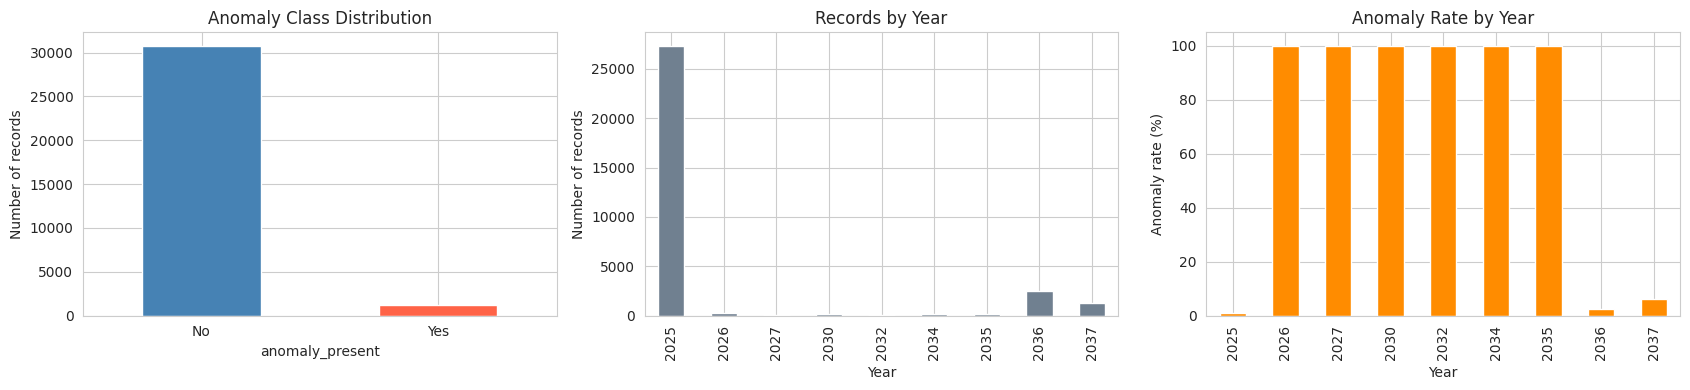

          records  anomaly_rate_%
start_dt                         
2025        27336            1.02
2026          245          100.00
2027           69          100.00
2030          125          100.00
2032           99          100.00
2034          136          100.00
2035          137          100.00
2036         2538            2.60
2037         1315            6.01

Note: years with very few records give unreliable anomaly rates.


In [ ]:
# Temporary 0/1 target just for plotting (the official target is built in Section 8)
eda_target = df["anomaly_present"].map({"No": 0, "Yes": 1})
year = df["start_dt"].dt.year

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

df["anomaly_present"].value_counts().plot(kind="bar", ax=axes[0], color=["steelblue", "tomato"])
axes[0].set_title("Anomaly Class Distribution")
axes[0].set_xlabel("anomaly_present"); axes[0].set_ylabel("Number of records")
axes[0].tick_params(axis="x", rotation=0)

year.value_counts().sort_index().plot(kind="bar", ax=axes[1], color="slategray")
axes[1].set_title("Records by Year")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Number of records")

rate_by_year = eda_target.groupby(year).mean() * 100
rate_by_year.plot(kind="bar", ax=axes[2], color="darkorange")
axes[2].set_title("Anomaly Rate by Year")
axes[2].set_xlabel("Year"); axes[2].set_ylabel("Anomaly rate (%)")
plt.tight_layout(); plt.show()

print(pd.DataFrame({"records": year.value_counts().sort_index(),
                    "anomaly_rate_%": rate_by_year.round(2)}))
print("\nNote: years with very few records give unreliable anomaly rates.")

Plotting KPIs: ['RSRP', 'DL_BLER', 'DL_MCS', 'UL_BLER', 'UL_MCS', 'UL_NPRB']


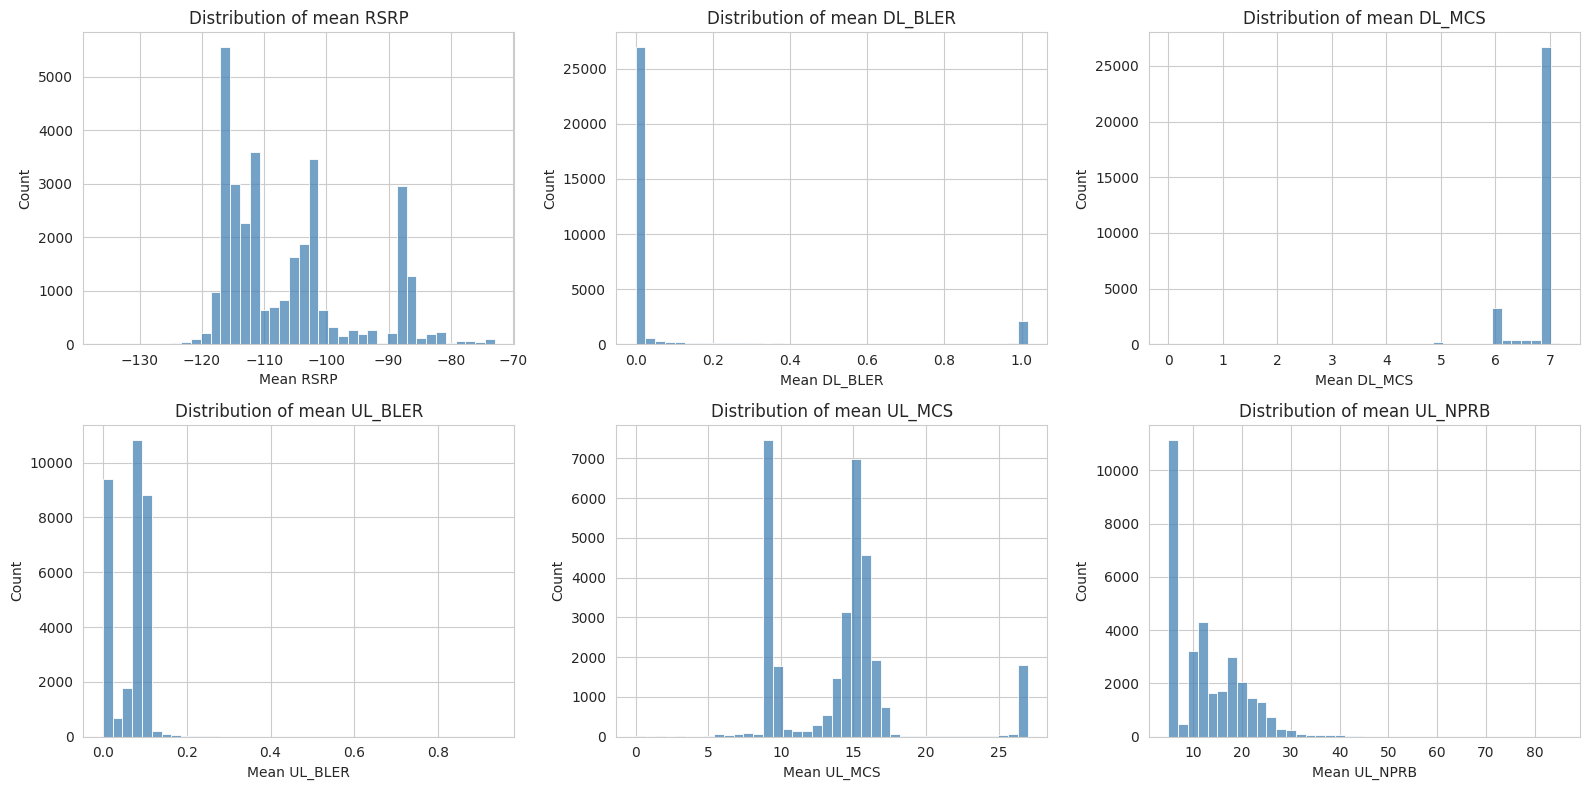

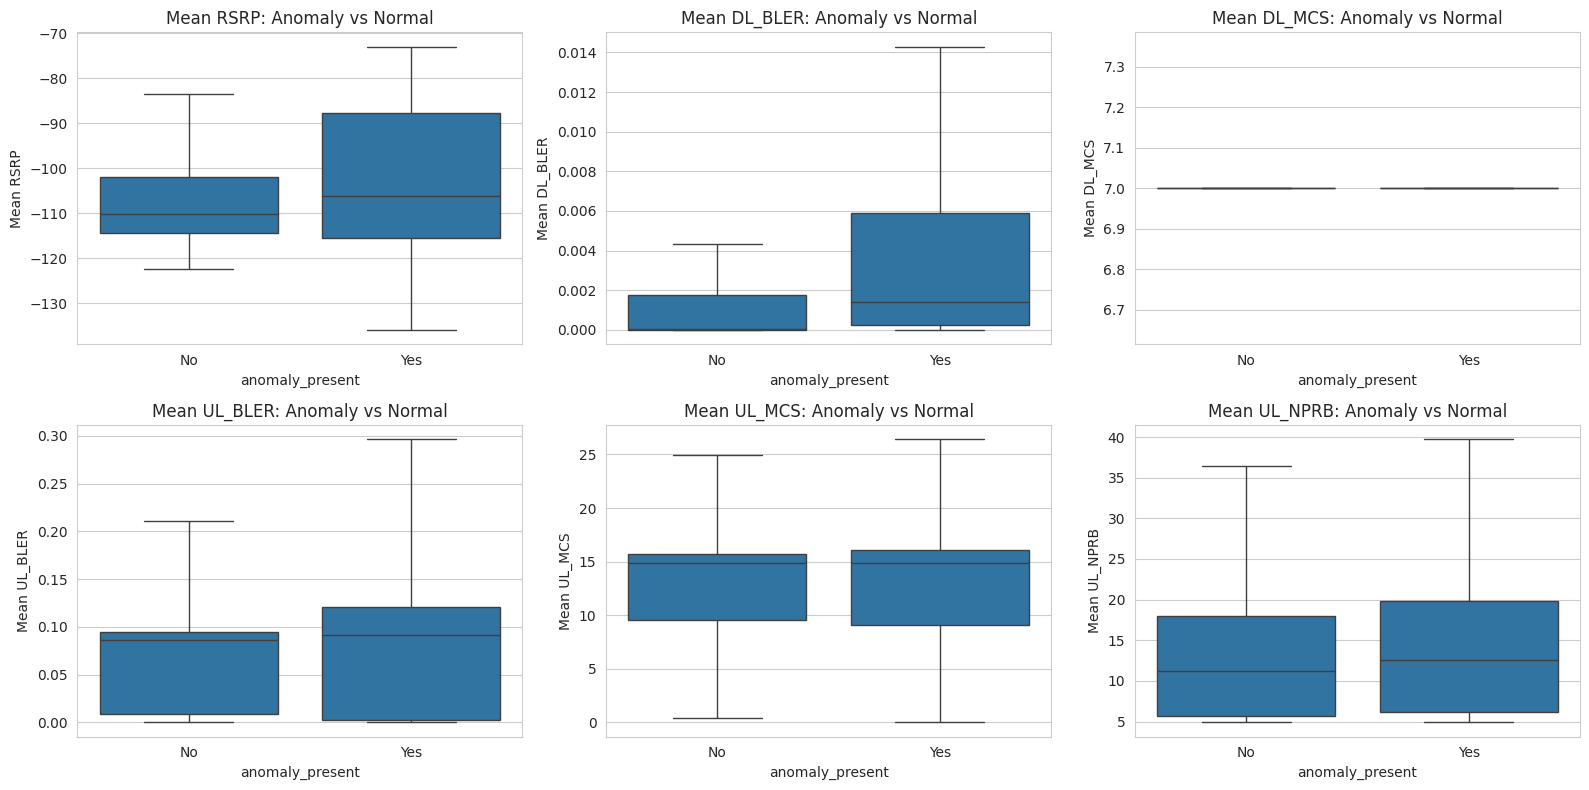

In [ ]:
# One mean value per KPI per record (quick summary used for EDA only)
def kpi_mean(d, k):
    if isinstance(d, dict) and k in d:
        a = to_array(d[k])
        if a is not None:
            a = a[np.isfinite(a)]
            if a.size > 0:
                return a.mean()
    return np.nan

kpi_means = pd.DataFrame({k: df["KPIs_parsed"].apply(lambda d: kpi_mean(d, k)) for k in kpi_names})
plot_kpis = kpi_names[:6]
print("Plotting KPIs:", plot_kpis)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, k in zip(axes.ravel(), plot_kpis):
    sns.histplot(kpi_means[k].dropna(), bins=40, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of mean {k}"); ax.set_xlabel(f"Mean {k}"); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, k in zip(axes.ravel(), plot_kpis):
    plot_df = pd.DataFrame({"anomaly_present": df["anomaly_present"], k: kpi_means[k]}).dropna()
    sns.boxplot(data=plot_df, x="anomaly_present", y=k, order=["No", "Yes"], showfliers=False, ax=ax)
    ax.set_title(f"Mean {k}: Anomaly vs Normal"); ax.set_xlabel("anomaly_present"); ax.set_ylabel(f"Mean {k}")
plt.tight_layout(); plt.show()

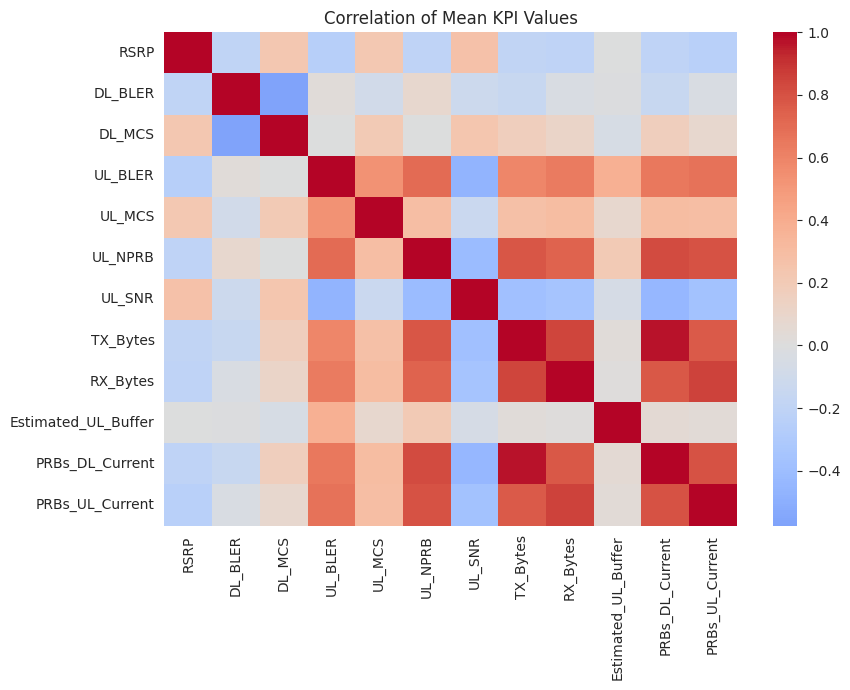

In [ ]:
#Corelation Of KPI Values
corr_cols = kpi_names[:12]
plt.figure(figsize=(9, 7))
sns.heatmap(kpi_means[corr_cols].corr(), annot=len(corr_cols) <= 8, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of Mean KPI Values")
plt.tight_layout(); plt.show()

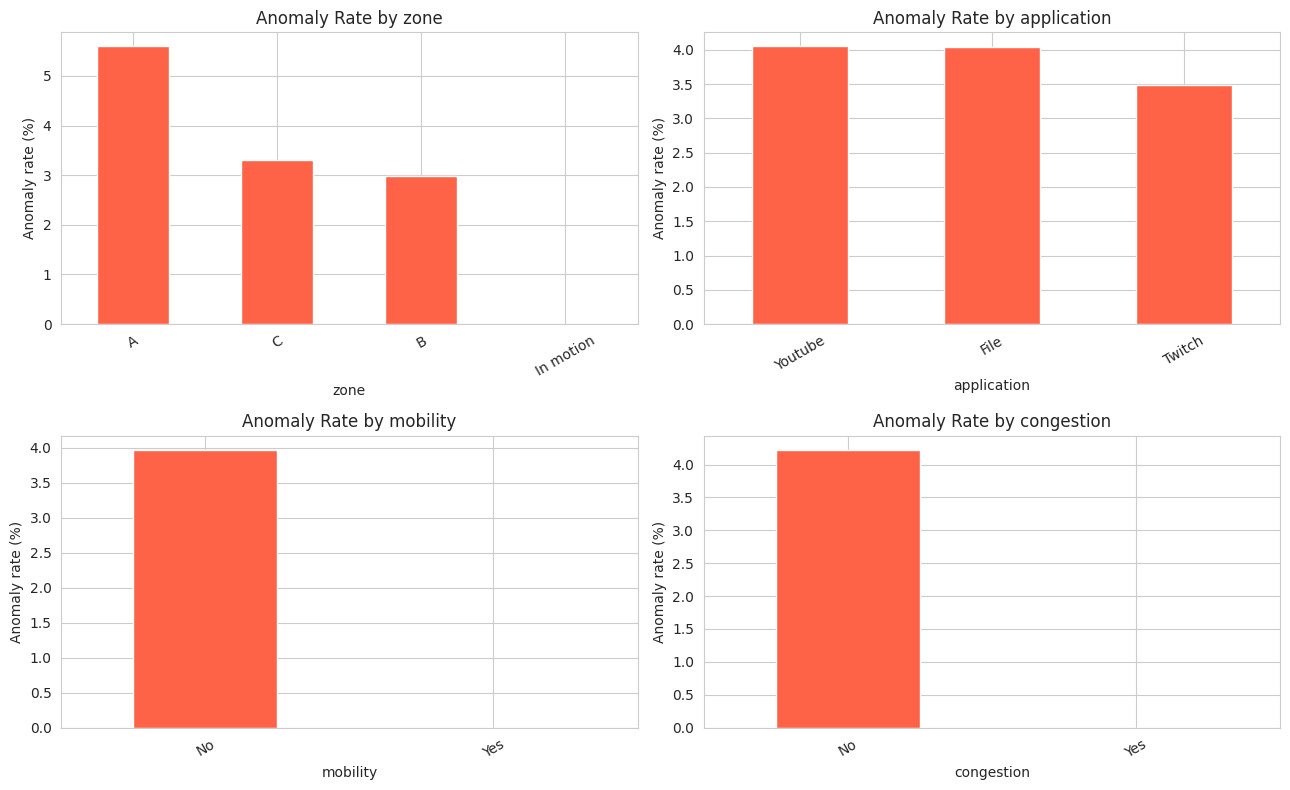

In [ ]:
cat_labels = ["zone", "application", "mobility", "congestion"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), cat_labels):
    rate = (eda_target.groupby(df[c]).mean() * 100).sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="tomato")
    ax.set_title(f"Anomaly Rate by {c}"); ax.set_xlabel(c); ax.set_ylabel("Anomaly rate (%)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

Feature Engineering

In [ ]:
STAT_NAMES = ["mean", "std", "min", "max", "median"]
rows = []
for d in df["KPIs_parsed"]:
    row = {}
    for k in kpi_names:
        a = to_array(d[k]) if isinstance(d, dict) and k in d else None
        if a is not None:
            a = a[np.isfinite(a)]
            if a.size == 0:
                a = None
        vals = [np.nan] * 5 if a is None else [a.mean(), a.std(), a.min(), a.max(), np.median(a)]
        for s, v in zip(STAT_NAMES, vals):
            row[f"{k}_{s}"] = v
    rows.append(row)
kpi_feats = pd.DataFrame(rows, index=df.index)
print("KPI-derived features:", kpi_feats.shape)
kpi_feats.head(3)

KPI-derived features: (32000, 90)


,RSRP_mean,RSRP_std,RSRP_min,RSRP_max,RSRP_median,DL_BLER_mean,DL_BLER_std,DL_BLER_min,DL_BLER_max,DL_BLER_median,DL_MCS_mean,DL_MCS_std,DL_MCS_min,DL_MCS_max,DL_MCS_median,UL_BLER_mean,UL_BLER_std,UL_BLER_min,UL_BLER_max,UL_BLER_median,UL_MCS_mean,UL_MCS_std,UL_MCS_min,UL_MCS_max,UL_MCS_median,...,PRB_Utilization_UL_mean,PRB_Utilization_UL_std,PRB_Utilization_UL_min,PRB_Utilization_UL_max,PRB_Utilization_UL_median,UL_Protocol_mean,UL_Protocol_std,UL_Protocol_min,UL_Protocol_max,UL_Protocol_median,UL_NumberOfPackets_mean,UL_NumberOfPackets_std,UL_NumberOfPackets_min,UL_NumberOfPackets_max,UL_NumberOfPackets_median,DL_Protocol_mean,DL_Protocol_std,DL_Protocol_min,DL_Protocol_max,DL_Protocol_median,DL_NumberOfPackets_mean,DL_NumberOfPackets_std,DL_NumberOfPackets_min,DL_NumberOfPackets_max,DL_NumberOfPackets_median
0,-73.232266,0.495679,-75.0,-73.0,-73.0,0.010302,0.015408,0.00000,0.059794,0.002536,7.0,0.0,7.0,7.0,7.0,0.088510,0.033956,0.023125,0.171720,0.082702,15.856250,2.299661,9.00,18.0,17.000,...,1.672912,0.941679,0.0472,4.7924,1.75480,NaN,NaN,NaN,NaN,NaN,76.273438,26.976180,20.0,189.0,72.5,NaN,NaN,NaN,NaN,NaN,282.312500,299.763807,0.0,1926.0,247.0
1,-73.000000,0.000000,-73.0,-73.0,-73.0,0.008302,0.013705,0.00001,0.061595,0.001921,7.0,0.0,7.0,7.0,7.0,0.102627,0.038901,0.025557,0.182464,0.106558,15.425781,1.983697,9.00,17.0,16.000,...,1.463232,0.625033,0.0944,3.9341,1.40105,NaN,NaN,NaN,NaN,NaN,71.070312,16.495825,32.0,131.0,71.0,NaN,NaN,NaN,NaN,NaN,270.632812,278.073587,0.0,1706.0,214.0
2,-73.000000,0.000000,-73.0,-73.0,-73.0,0.011597,0.016540,0.00000,0.065248,0.001724,7.0,0.0,7.0,7.0,7.0,0.094174,0.046233,0.020622,0.183984,0.087723,16.097578,2.328200,8.46,19.0,16.765,...,1.732455,1.068903,0.0472,6.4814,1.70760,NaN,NaN,NaN,NaN,NaN,75.921875,26.423122,18.0,195.0,72.0,NaN,NaN,NaN,NaN,NaN,298.101562,247.815261,0.0,1821.0,277.5


In [ ]:
def flatten_numeric(obj, prefix=""):
    """Collect scalar numeric values from a nested dict (arrays/text are skipped)."""
    out = {}
    if isinstance(obj, dict):
        for k, v in obj.items():
            out.update(flatten_numeric(v, f"{prefix}_{k}" if prefix else str(k)))
    elif isinstance(obj, (int, float, np.integer, np.floating)) and not isinstance(obj, bool):
        out[prefix] = float(obj)
    return out

stats_feats = pd.DataFrame([flatten_numeric(d) for d in df["statistics_parsed"]], index=df.index)
stats_feats = stats_feats.add_prefix("stat_").replace([np.inf, -np.inf], np.nan)
print("Supplied numeric statistics:", stats_feats.shape)

if stats_feats.shape[1] > 0:
    corr = pd.concat([kpi_feats, stats_feats], axis=1).corr()
    max_corr = corr.loc[stats_feats.columns, kpi_feats.columns].abs().max(axis=1)
    print("Max |correlation| of each supplied statistic with our KPI features:")
    print(max_corr.describe())
    redundant = max_corr[max_corr > 0.95].index.tolist()
    print(f"\n{len(redundant)} of {stats_feats.shape[1]} supplied statistics are redundant (|r| > 0.95) and will be dropped.")
    stats_keep = stats_feats.drop(columns=redundant)
else:
    stats_keep = stats_feats
print("Supplied statistics kept:", stats_keep.shape[1])

Supplied numeric statistics: (32000, 64)
Max |correlation| of each supplied statistic with our KPI features:
count    64.000000
mean      0.575664
std       0.399584
min       0.025131
25%       0.156372
50%       0.663407
75%       0.999213
max       1.000000
dtype: float64

20 of 64 supplied statistics are redundant (|r| > 0.95) and will be dropped.
Supplied statistics kept: 44


In [ ]:
# Suitability check for categorical context labels
cat_candidates = ["zone", "application", "mobility", "congestion"]
cat_cols = []
for c in cat_candidates:
    n_unique = df[c].nunique(dropna=True)
    miss = df[c].isna().mean() * 100
    rates = eda_target.groupby(df[c]).mean() * 100
    print(f"{c}: {n_unique} categories, {miss:.1f}% missing, anomaly rate range {rates.min():.2f}%-{rates.max():.2f}%")
    if 2 <= n_unique <= 20:
        cat_cols.append(c)
    else:
        print(f"   -> skipped (needs 2 to 20 categories)")
print("Categorical features used:", cat_cols)

sampling_num = pd.to_numeric(df["sampling_rate"], errors="coerce")
use_sampling = sampling_num.notna().mean() >= 0.99
print("sampling_rate numeric and usable:", use_sampling)

zone: 4 categories, 0.0% missing, anomaly rate range 0.00%-5.60%
application: 3 categories, 0.0% missing, anomaly rate range 3.48%-4.05%
mobility: 2 categories, 0.0% missing, anomaly rate range 0.00%-3.97%
congestion: 2 categories, 0.0% missing, anomaly rate range 0.00%-4.23%
Categorical features used: ['zone', 'application', 'mobility', 'congestion']
sampling_rate numeric and usable: True


In [ ]:
parts = [kpi_feats, stats_keep]
if use_sampling:
    parts.append(sampling_num.rename("sampling_rate_num").to_frame())
X_all = pd.concat(parts, axis=1)
num_cols = list(X_all.columns)

# infinite -> NaN (imputed later using TRAINING medians only)
X_all[num_cols] = X_all[num_cols].replace([np.inf, -np.inf], np.nan)

# remove constant / empty features
constant = [c for c in num_cols if X_all[c].nunique(dropna=True) <= 1]
print("Constant or empty features removed:", len(constant))
num_cols = [c for c in num_cols if c not in constant]

# remove near-duplicate features (|r| > 0.98), keep the first of each pair
corr_abs = X_all[num_cols].corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
redundant_num = [c for c in upper.columns if (upper[c] > 0.98).any()]
print("Near-duplicate features removed:", len(redundant_num))
num_cols = [c for c in num_cols if c not in redundant_num]

# add categorical features (missing label becomes its own 'Unknown' category)
for c in cat_cols:
    X_all[c] = df[c].fillna("Unknown").astype(str)

feature_cols = num_cols + cat_cols
X_all = X_all[feature_cols]
print("Final feature count:", len(feature_cols), f"({len(num_cols)} numeric, {len(cat_cols)} categorical)")
print("Missing values left (will be imputed in the pipeline):", int(X_all[num_cols].isna().sum().sum()))
print("Shape:", X_all.shape)

Constant or empty features removed: 11
Near-duplicate features removed: 18
Final feature count: 110 (106 numeric, 4 categorical)
Missing values left (will be imputed in the pipeline): 0
Shape: (32000, 110)


Target Preparation and Leakage Prevention

In [ ]:
#Target and Leakage Prevention
y_all = df["anomaly_present"].map({"No": 0, "Yes": 1})
unexpected = df.loc[y_all.isna(), "anomaly_present"].unique()
print("Records with missing/unexpected target:", y_all.isna().sum(), unexpected)
valid = y_all.notna()                      # only rows with a known label are used for modelling
print("Records used for modelling:", valid.sum(), "of", len(df))

counts = y_all[valid].astype(int).value_counts().sort_index()
print("\nClass counts (0=No, 1=Yes):\n", counts)
print(f"Positive rate: {counts.get(1, 0) / counts.sum() * 100:.2f}%  -> imbalanced target")

# ---- leakage guard ----
forbidden = ["anomaly_present", "description", "QnA", "anomalies", "labels"]
leaks = [c for c in X_all.columns if any(c == f or c.startswith(f + "_") for f in forbidden)]
assert not leaks, f"Leakage risk, remove: {leaks}"
assert len(X_all) == len(y_all) and (X_all.index == y_all.index).all(), "Features and target are misaligned"
print("\nLeakage check passed. Features and target are aligned.")

# ---- is there an outage/availability target? ----
keywords = ["outage", "unavail", "availability", "downtime", "service_down", "failure"]
searched = list(df.columns) + list(first_valid("labels_parsed").keys()) + kpi_names
hits = [s for s in searched if any(w in str(s).lower() for w in keywords)]
print("\nOutage/availability-related fields found:", hits if hits else "NONE")
if not hits:
    print("Conclusion: no defensible outage label exists. We keep anomaly classification as the task.")

Records with missing/unexpected target: 0 []
Records used for modelling: 32000 of 32000

Class counts (0=No, 1=Yes):
 anomaly_present
0    30765
1     1235
Name: count, dtype: int64
Positive rate: 3.86%  -> imbalanced target

Leakage check passed. Features and target are aligned.

Outage/availability-related fields found: NONE
Conclusion: no defensible outage label exists. We keep anomaly classification as the task.


Spliting Data And Training Models

In [ ]:
reasons = []
n_nat = df["start_dt"].isna().sum() + df["end_dt"].isna().sum()
n_neg = (df["duration_sec"] <= 0).sum()
n_future = (df["start_dt"] > pd.Timestamp.now(tz="UTC")).sum()
if n_nat > 0:    reasons.append(f"{n_nat} invalid timestamps")
if n_neg > 0:    reasons.append(f"{n_neg} records with end_time <= start_time")
if n_future > 0: reasons.append(f"{n_future} records dated in the future (up to {df['start_dt'].max().year})")
timestamps_reliable = len(reasons) == 0
reliability_reasons = reasons
print("Timestamps reliable:", timestamps_reliable)
print("Reasons for doubt:", reasons if reasons else "none")

model_df = X_all.loc[valid].copy()
model_df["target"] = y_all[valid].astype(int)
model_df["start_dt"] = df.loc[valid, "start_dt"]

def stratified_split(m):
    train, tmp = train_test_split(m, test_size=0.30, stratify=m["target"], random_state=RANDOM_STATE)
    val, test = train_test_split(tmp, test_size=0.50, stratify=tmp["target"], random_state=RANDOM_STATE)
    return train, val, test

split_method = None
if timestamps_reliable:
    m = model_df.sort_values("start_dt").reset_index(drop=True)
    n = len(m)
    train_df, val_df, test_df = m.iloc[:int(.70 * n)], m.iloc[int(.70 * n):int(.85 * n)], m.iloc[int(.85 * n):]
    if min(train_df["target"].sum(), val_df["target"].sum(), test_df["target"].sum()) > 0:
        split_method = "Chronological 70/15/15"
    else:
        print("A chronological split left a set with no anomalies -> using stratified split instead.")
if split_method is None:
    train_df, val_df, test_df = stratified_split(model_df)
    split_method = "Stratified 70/15/15 (retrospective classification only; timestamps unreliable)"

print("\nSplit method:", split_method)
X_train, y_train = train_df[feature_cols], train_df["target"]
X_val,   y_val   = val_df[feature_cols],   val_df["target"]
X_test,  y_test  = test_df[feature_cols],  test_df["target"]
print(pd.DataFrame({"records": [len(y_train), len(y_val), len(y_test)],
                    "anomalies": [y_train.sum(), y_val.sum(), y_test.sum()],
                    "anomaly_rate_%": [round(y.mean() * 100, 2) for y in (y_train, y_val, y_test)]},
                   index=["train", "validation", "test"]))

Timestamps reliable: False
Reasons for doubt: ['4419 records dated in the future (up to 2037)']

Split method: Stratified 70/15/15 (retrospective classification only; timestamps unreliable)
            records  anomalies  anomaly_rate_%
train         22400        865            3.86
validation     4800        185            3.85
test           4800        185            3.85


In [ ]:
def build_pipeline(model, scale):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    transformers = [("num", Pipeline(num_steps), num_cols)]
    if cat_cols:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols))
    return Pipeline([("prep", ColumnTransformer(transformers)), ("model", model)])

models = {
    "Dummy (baseline)": build_pipeline(DummyClassifier(strategy="most_frequent"), scale=False),
    "Logistic Regression": build_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE), scale=True),
    "Random Forest": build_pipeline(
        RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
                               n_jobs=-1, random_state=RANDOM_STATE), scale=False),
}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print("Trained:", name)

Trained: Dummy (baseline)
Trained: Logistic Regression
Trained: Random Forest


Model Evaluation

In [ ]:
def evaluate(pipe, X, y):
    pred = pipe.predict(X)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "False Alarm Rate": fp / (fp + tn) if (fp + tn) > 0 else np.nan,
            "TP": tp, "FP": fp, "TN": tn, "FN": fn}

val_results = pd.DataFrame({n: evaluate(p, X_val, y_val) for n, p in models.items()}).T
test_results = pd.DataFrame({n: evaluate(p, X_test, y_test) for n, p in models.items()}).T

print("VALIDATION results"); display(val_results.round(4))
print("TEST results");       display(test_results.round(4))

VALIDATION results


,Accuracy,Precision,Recall,F1,False Alarm Rate,TP,FP,TN,FN
Dummy (baseline),0.9615,0.0000,0.0000,0.0000,0.0000,0.0,0.0,4615.0,185.0
Logistic Regression,0.9665,0.5361,0.9622,0.6886,0.0334,178.0,154.0,4461.0,7.0
Random Forest,0.9975,1.0000,0.9351,0.9665,0.0000,173.0,0.0,4615.0,12.0


TEST results


,Accuracy,Precision,Recall,F1,False Alarm Rate,TP,FP,TN,FN
Dummy (baseline),0.9615,0.0000,0.0000,0.0000,0.0000,0.0,0.0,4615.0,185.0
Logistic Regression,0.9694,0.5605,0.9514,0.7054,0.0299,176.0,138.0,4477.0,9.0
Random Forest,0.9969,1.0000,0.9189,0.9577,0.0000,170.0,0.0,4615.0,15.0


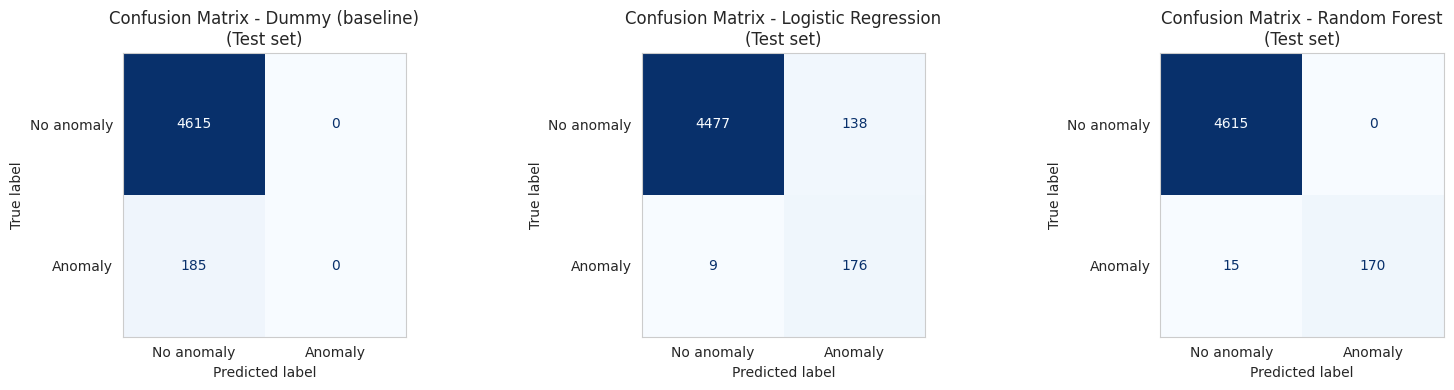

===== Dummy (baseline) (test) =====
              precision    recall  f1-score   support

  No anomaly       0.96      1.00      0.98      4615
     Anomaly       0.00      0.00      0.00       185

    accuracy                           0.96      4800
   macro avg       0.48      0.50      0.49      4800
weighted avg       0.92      0.96      0.94      4800

===== Logistic Regression (test) =====
              precision    recall  f1-score   support

  No anomaly       1.00      0.97      0.98      4615
     Anomaly       0.56      0.95      0.71       185

    accuracy                           0.97      4800
   macro avg       0.78      0.96      0.84      4800
weighted avg       0.98      0.97      0.97      4800

===== Random Forest (test) =====
              precision    recall  f1-score   support

  No anomaly       1.00      1.00      1.00      4615
     Anomaly       1.00      0.92      0.96       185

    accuracy                           1.00      4800
   macro avg       1

In [ ]:
# Confusion matrices on the test set
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, pipe) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pipe.predict(X_test), labels=[0, 1],
                                            display_labels=["No anomaly", "Anomaly"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Confusion Matrix - {name}\n(Test set)")
    ax.grid(False)
plt.tight_layout(); plt.show()

for name, pipe in models.items():
    print(f"===== {name} (test) =====")
    print(classification_report(y_test, pipe.predict(X_test), target_names=["No anomaly", "Anomaly"], zero_division=0))

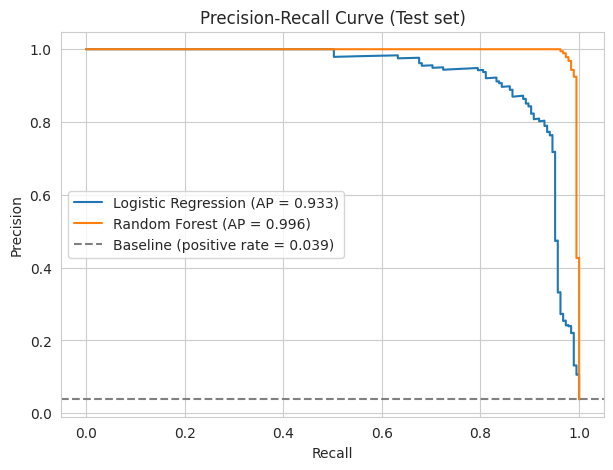

In [ ]:
# Precision-recall curves on the test set
plt.figure(figsize=(7, 5))
for name in ["Logistic Regression", "Random Forest"]:
    proba = models[name].predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, proba)
    plt.plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_test, proba):.3f})")
plt.axhline(y_test.mean(), color="gray", linestyle="--", label=f"Baseline (positive rate = {y_test.mean():.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curve (Test set)")
plt.legend(); plt.show()

## 12. Model Comparison
The best model is chosen by **validation F1-score** (not accuracy, and not the test set). The false alarm rate is shown next to it so we can check that the choice is acceptable. The test set is only used to report the final performance.

In [ ]:
comparison = pd.concat({"Validation": val_results[["Accuracy", "Precision", "Recall", "F1", "False Alarm Rate"]],
                        "Test": test_results[["Accuracy", "Precision", "Recall", "F1", "False Alarm Rate"]]}, axis=1)
display(comparison.round(4))

candidates = val_results.drop(index="Dummy (baseline)")
best_name = candidates["F1"].astype(float).idxmax()
best_pipe = models[best_name]
print(f"Best model by validation F1: {best_name}")
print(f"  Validation F1 = {val_results.loc[best_name, 'F1']:.4f}, "
      f"Recall = {val_results.loc[best_name, 'Recall']:.4f}, "
      f"False alarm rate = {val_results.loc[best_name, 'False Alarm Rate']:.4f}")
print(f"  Test       F1 = {test_results.loc[best_name, 'F1']:.4f}, "
      f"Recall = {test_results.loc[best_name, 'Recall']:.4f}, "
      f"False alarm rate = {test_results.loc[best_name, 'False Alarm Rate']:.4f}")

Validation                                             \
                      Accuracy Precision  Recall      F1 False Alarm Rate   
Dummy (baseline)        0.9615    0.0000  0.0000  0.0000           0.0000   
Logistic Regression     0.9665    0.5361  0.9622  0.6886           0.0334   
Random Forest           0.9975    1.0000  0.9351  0.9665           0.0000   

                        Test                                             
                    Accuracy Precision  Recall      F1 False Alarm Rate  
Dummy (baseline)      0.9615    0.0000  0.0000  0.0000           0.0000  
Logistic Regression   0.9694    0.5605  0.9514  0.7054           0.0299  
Random Forest         0.9969    1.0000  0.9189  0.9577           0.0000

Best model by validation F1: Random Forest
  Validation F1 = 0.9665, Recall = 0.9351, False alarm rate = 0.0000
  Test       F1 = 0.9577, Recall = 0.9189, False alarm rate = 0.0000


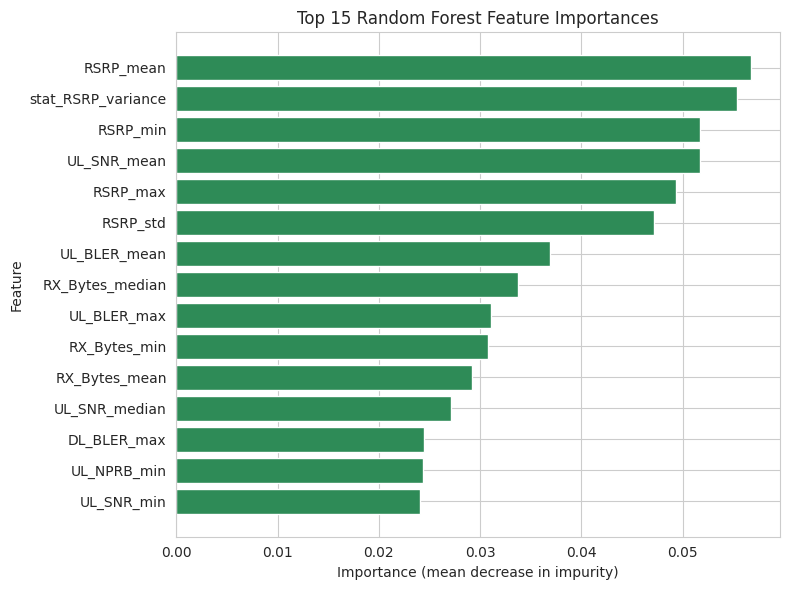

RSRP_mean             0.0568
stat_RSRP_variance    0.0554
RSRP_min              0.0518
UL_SNR_mean           0.0517
RSRP_max              0.0493
RSRP_std              0.0472
UL_BLER_mean          0.0369
RX_Bytes_median       0.0337
UL_BLER_max           0.0310
RX_Bytes_min          0.0308
dtype: float64


In [ ]:
#Feature Importance
rf_pipe = models["Random Forest"]
names = [n.split("__", 1)[1] for n in rf_pipe.named_steps["prep"].get_feature_names_out()]
importances = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)

top = importances.head(15).sort_values()
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color="seagreen")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance (mean decrease in impurity)"); plt.ylabel("Feature")
plt.tight_layout(); plt.show()
print(importances.head(10).round(4))

In [ ]:
#Predictions
pos = test_df[test_df["target"] == 1]
neg = test_df[test_df["target"] == 0]
demo = pd.concat([pos.sample(min(5, len(pos)), random_state=RANDOM_STATE),
                  neg.sample(min(5, len(neg)), random_state=RANDOM_STATE)])

proba = best_pipe.predict_proba(demo[feature_cols])[:, 1]
pred = best_pipe.predict(demo[feature_cols])
label_text = {0: "No anomaly", 1: "Anomaly"}
demo_table = pd.DataFrame({
    "start_time": demo["start_dt"].values,
    "anomaly_probability": proba.round(4),
    "predicted_class": [label_text[p] for p in pred],
    "actual_class": [label_text[t] for t in demo["target"]],
}, index=demo.index)
demo_table["correct"] = demo_table["predicted_class"] == demo_table["actual_class"]
print(f"Model used: {best_name}")
display(demo_table)

def predict_record(test_row_index):
    """Predict one held-out record by its index in test_df."""
    row = test_df.loc[[test_row_index], feature_cols]
    p = best_pipe.predict_proba(row)[0, 1]
    return {"anomaly_probability": round(float(p), 4),
            "predicted": label_text[int(p >= 0.5)],
            "actual": label_text[int(test_df.loc[test_row_index, "target"])]}

print("Example single-record prediction:", predict_record(demo.index[0]))

Model used: Random Forest


,start_time,anomaly_probability,predicted_class,actual_class,correct
267,2025-01-03 00:02:00.200,0.8373,Anomaly,Anomaly,True
877,2027-07-07 00:05:36.000,0.8090,Anomaly,Anomaly,True
685,2035-11-28 00:03:50.400,0.9691,Anomaly,Anomaly,True
8,2025-01-01 00:09:08.300,0.9342,Anomaly,Anomaly,True
944,2034-12-20 00:05:20.000,0.9694,Anomaly,Anomaly,True
26103,2025-05-21 00:34:27.200,0.0000,No anomaly,No anomaly,True
13679,2025-07-30 01:57:07.200,0.0000,No anomaly,No anomaly,True
19007,2025-04-23 00:25:55.200,0.0000,No anomaly,No anomaly,True
17233,2025-04-23 01:55:44.000,0.0000,No anomaly,No anomaly,True
23536,2025-09-10 02:33:45.600,0.0046,No anomaly,No anomaly,True


Example single-record prediction: {'anomaly_probability': 0.8373, 'predicted': 'Anomaly', 'actual': 'Anomaly'}


In [ ]:
print("FINAL REPORT")
print("--" * 60)
print(f"Records loaded: {len(df)} | used for modelling: {len(model_df)}")
print(f"Features used: {len(feature_cols)} ({len(num_cols)} numeric, {len(cat_cols)} categorical)")
print(f"Anomaly rate in modelling data: {model_df['target'].mean() * 100:.2f}%")
print(f"Timestamps reliable: {timestamps_reliable}" + (f"  (issues: {'; '.join(reliability_reasons)})" if reliability_reasons else ""))
print(f"Split method: {split_method}")
print(f"Outage/availability label found: {'YES: ' + str(hits) if hits else 'NO - task remains anomaly classification'}")
print("\nTest-set results:")
print(test_results[["Accuracy", "Precision", "Recall", "F1", "False Alarm Rate"]].round(4).to_string())
print(f"\nBest model (by validation F1): {best_name}")
print("Top 5 features (Random Forest):", list(importances.head(5).index))

FINAL REPORT (generated from this notebook run)
Records loaded: 32000 | used for modelling: 32000
Features used: 110 (106 numeric, 4 categorical)
Anomaly rate in modelling data: 3.86%
Timestamps reliable: False  (issues: 4419 records dated in the future (up to 2037))
Split method: Stratified 70/15/15 (retrospective classification only; timestamps unreliable)
Outage/availability label found: NO - task remains anomaly classification

Test-set results:
                     Accuracy  Precision  Recall      F1  False Alarm Rate
Dummy (baseline)       0.9615     0.0000  0.0000  0.0000            0.0000
Logistic Regression    0.9694     0.5605  0.9514  0.7054            0.0299
Random Forest          0.9969     1.0000  0.9189  0.9577            0.0000

Best model (by validation F1): Random Forest
Top 5 features (Random Forest): ['RSRP_mean', 'stat_RSRP_variance', 'RSRP_min', 'UL_SNR_mean', 'RSRP_max']

Reminder: this is retrospective anomaly classification, not future outage prediction.
